In [1]:
from google.colab import files
import zipfile, io, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

uploaded = files.upload()

ENERGIES = [8.192, 32.768, 65.536]
REFERENCE_SEED = 20261020
CUT_GEV = 0.01  # 10 MeV analysis cutoff

def find_member(zf, suffix):
    matches = [n for n in zf.namelist() if n.endswith(suffix)]
    if len(matches) != 1:
        raise ValueError(f"Expected one file ending in {suffix}; found {len(matches)}")
    return matches[0]

def read_json(zf, suffix):
    return json.loads(zf.read(find_member(zf, suffix)))

def read_npz(zf, suffix):
    with np.load(
        io.BytesIO(zf.read(find_member(zf, suffix))),
        allow_pickle=False
    ) as f:
        return {k: f[k].copy() for k in f.files}

runs = {}

for filename, payload in uploaded.items():
    if not filename.lower().endswith(".zip"):
        continue

    with zipfile.ZipFile(io.BytesIO(payload)) as zf:
        try:
            manifest = read_json(zf, "manifest.json")
            geometry = read_json(zf, "photon_geometry.json")
        except ValueError:
            print("Skipping non-run ZIP:", filename)
            continue

        seed = int(manifest["config"]["seed"])
        run_data = {}

        for E in ENERGIES:
            prefix = f"arrays/photon_{E:.3f}GeV_"
            run_data[E] = {
                "reference": read_npz(
                    zf, prefix + "reference_run-1.npz"
                ),
                "generator_run0": read_npz(
                    zf, prefix + "generator_run0.npz"
                ),
                "generator_run1": read_npz(
                    zf, prefix + "generator_run1.npz"
                ),
                "scale_only": read_npz(
                    zf, prefix + "scale_only_run-1.npz"
                ),
            }

        runs[seed] = {"geometry": geometry, "data": run_data}

assert REFERENCE_SEED in runs, (
    "Please upload the ZIP for seed 20261020 as well."
)
assert len(runs) == 3, (
    f"Expected three individual run ZIPs, but loaded {len(runs)}."
)

print("Loaded seeds:", sorted(runs))
print("Analysis cutoff:", CUT_GEV, "GeV")

Saving validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip to validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip
Saving validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip to validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip
Saving validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip to validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip
Loaded seeds: [20261020, 20261021, 20261022]
Analysis cutoff: 0.01 GeV


In [2]:
# Build the native-cell map directly from the geometry JSON.
geometry = runs[REFERENCE_SEED]["geometry"]

cell_metadata = []
layer_slices = {}
cell_idx = 0

for ordinal, (layer_id, n_angles, edges) in enumerate(zip(
    geometry["layer_ids"],
    geometry["n_angles"],
    geometry["radial_edges"]
)):
    start = cell_idx

    # Native order: layer, angle, radial bin
    for angle in range(int(n_angles)):
        for radial_bin in range(len(edges) - 1):
            r_low = float(edges[radial_bin])
            r_high = float(edges[radial_bin + 1])

            cell_metadata.append({
                "cell_index": cell_idx,
                "layer_ordinal": ordinal,
                "layer_id": int(layer_id),
                "angle_index": angle,
                "radial_bin": radial_bin,
                "r_low_XML": r_low,
                "r_high_XML": r_high,
                "r_center_XML": (r_low + r_high) / 2,
            })
            cell_idx += 1

    layer_slices[int(layer_id)] = (start, cell_idx)

cell_df = pd.DataFrame(cell_metadata)
radial_centers = cell_df["r_center_XML"].to_numpy()

final_layer_id = int(geometry["layer_ids"][-1])
layer_start, layer_end = layer_slices[final_layer_id]
outer_cell_index = layer_end - 1

print("Total native cells:", len(cell_df))
print("Final layer ID:", final_layer_id)
print("Final layer cell indices:", layer_start, "to", layer_end - 1)
print("Outermost cell index:", outer_cell_index)

display(cell_df.tail(8))

Total native cells: 368
Final layer ID: 12
Final layer cell indices: 363 to 367
Outermost cell index: 367


,cell_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML
360,360,3,3,0,2,100.0,200.0,150.0
361,361,3,3,0,3,200.0,400.0,300.0
362,362,3,3,0,4,400.0,600.0,500.0
363,363,4,12,0,0,0.0,100.0,50.0
364,364,4,12,0,1,100.0,200.0,150.0
365,365,4,12,0,2,200.0,400.0,300.0
366,366,4,12,0,3,400.0,1000.0,700.0
367,367,4,12,0,4,1000.0,2000.0,1500.0


In [3]:
def apply_cut(native):
    native = np.asarray(native, dtype=float)
    return np.where(native >= CUT_GEV, native, 0.0)

def response_statistics(kept, energy):
    response = kept.sum(axis=1) / energy

    return {
        "n": len(response),
        "mean": np.mean(response),
        "std": np.std(response, ddof=1),
        "q05": np.quantile(response, 0.05),
        "q50": np.quantile(response, 0.50),
        "q90": np.quantile(response, 0.90),
        "q95": np.quantile(response, 0.95),
        "q99": np.quantile(response, 0.99),
        "max": np.max(response),
    }

def outer_statistics(kept):
    total = kept.sum(axis=1)

    final_layer_energy = kept[:, layer_start:layer_end].sum(axis=1)
    final_fraction = np.divide(
        final_layer_energy, total,
        out=np.zeros_like(total), where=total > 0
    )

    outer_energy = kept[:, outer_cell_index]
    outer_fraction = np.divide(
        outer_energy, total,
        out=np.zeros_like(total), where=total > 0
    )

    r_rms = np.sqrt(np.divide(
        (kept * radial_centers[None, :]**2).sum(axis=1),
        total,
        out=np.zeros_like(total),
        where=total > 0
    ))

    return {
        "n": len(kept),
        "final_layer_fraction_median": np.quantile(final_fraction, 0.50),
        "final_layer_fraction_q95": np.quantile(final_fraction, 0.95),
        "final_layer_fraction_q99": np.quantile(final_fraction, 0.99),
        "final_layer_fraction_max": np.max(final_fraction),
        "outer_cell_hit_rate": np.mean(outer_energy > 0),
        "outer_cell_rate_ge_0p1_GeV": np.mean(outer_energy >= 0.1),
        "outer_cell_rate_ge_1_GeV": np.mean(outer_energy >= 1.0),
        "outer_cell_q95_GeV": np.quantile(outer_energy, 0.95),
        "outer_cell_q99_GeV": np.quantile(outer_energy, 0.99),
        "outer_cell_max_GeV": np.max(outer_energy),
        "r_rms_q99_XML": np.quantile(r_rms, 0.99),
        "r_rms_max_XML": np.max(r_rms),
    }

response_rows = []
tail_rows = []
event_rows = []
plot_samples = {}

def add_summary(rows, energy, method, seed, kept, func):
    result = func(kept, energy) if func == response_statistics else func(kept)
    rows.append({
        "energy_GeV": energy,
        "method": method,
        "seed": str(seed),
        **result
    })

def add_event_rows(data, energy, seed, method, generation_run=None):
    raw = data["native"].astype(float)
    kept = apply_cut(raw)

    total = kept.sum(axis=1)
    final_energy = kept[:, layer_start:layer_end].sum(axis=1)
    final_fraction = np.divide(
        final_energy, total,
        out=np.zeros_like(total), where=total > 0
    )
    outer = kept[:, outer_cell_index]
    outer_fraction = np.divide(
        outer, total,
        out=np.zeros_like(total), where=total > 0
    )
    rms = np.sqrt(np.divide(
        (kept * radial_centers[None, :]**2).sum(axis=1),
        total,
        out=np.zeros_like(total), where=total > 0
    ))

    ids = data.get("event_id", np.arange(len(raw)))

    for i in range(len(raw)):
        event_rows.append({
            "energy_GeV": energy,
            "seed": seed,
            "method": method,
            "generation_run": generation_run,
            "row_index": i,
            "event_id": str(ids[i]),
            "deposited_GeV": total[i],
            "response": total[i] / energy,
            "final_layer_GeV": final_energy[i],
            "final_layer_fraction": final_fraction[i],
            "outermost_cell_GeV": outer[i],
            "outermost_cell_fraction": outer_fraction[i],
            "r_rms_XML": rms[i],
        })

for E in ENERGIES:
    # One fixed reference sample for every comparison.
    ref_data = runs[REFERENCE_SEED]["data"][E]["reference"]
    reference = apply_cut(ref_data["native"])

    add_summary(response_rows, E, "fixed_reference",
                f"fixed_{REFERENCE_SEED}", reference, response_statistics)
    add_summary(tail_rows, E, "fixed_reference",
                f"fixed_{REFERENCE_SEED}", reference, outer_statistics)

    add_event_rows(ref_data, E, REFERENCE_SEED, "fixed_reference")

    all_generators = []
    all_scale_only = []

    for seed in sorted(runs):
        data = runs[seed]["data"][E]

        g0 = apply_cut(data["generator_run0"]["native"])
        g1 = apply_cut(data["generator_run1"]["native"])
        generator = np.concatenate([g0, g1], axis=0)
        scale_only = apply_cut(data["scale_only"]["native"])

        all_generators.append(generator)
        all_scale_only.append(scale_only)

        add_summary(response_rows, E, "generator",
                    seed, generator, response_statistics)
        add_summary(response_rows, E, "scale_only",
                    seed, scale_only, response_statistics)

        add_summary(tail_rows, E, "generator",
                    seed, generator, outer_statistics)
        add_summary(tail_rows, E, "scale_only",
                    seed, scale_only, outer_statistics)

        add_event_rows(data["generator_run0"], E, seed,
                       "generator", generation_run=0)
        add_event_rows(data["generator_run1"], E, seed,
                       "generator", generation_run=1)
        add_event_rows(data["scale_only"], E, seed, "scale_only")

    pooled_generator = np.concatenate(all_generators, axis=0)
    pooled_scale = np.concatenate(all_scale_only, axis=0)

    add_summary(response_rows, E, "generator",
                "pooled_3_seeds", pooled_generator, response_statistics)
    add_summary(response_rows, E, "scale_only",
                "pooled_3_seeds", pooled_scale, response_statistics)

    add_summary(tail_rows, E, "generator",
                "pooled_3_seeds", pooled_generator, outer_statistics)
    add_summary(tail_rows, E, "scale_only",
                "pooled_3_seeds", pooled_scale, outer_statistics)

    plot_samples[E] = {
        "Fixed reference": reference,
        "Generator pooled": pooled_generator,
        "Scale-only pooled": pooled_scale,
    }

response_df = pd.DataFrame(response_rows)
tail_df = pd.DataFrame(tail_rows)
events_df = pd.DataFrame(event_rows)

print("Response comparison:")
display(response_df.sort_values(
    ["energy_GeV", "method", "seed"]
).round(5))

print("Outer-layer comparison at 65.536 GeV:")
display(tail_df[tail_df["energy_GeV"] == 65.536].round(5))

Response comparison:


,energy_GeV,method,seed,n,mean,std,q05,q50,q90,q95,q99,max
0,8.192,fixed_reference,fixed_20261020,300,0.92447,0.03130,0.87334,0.92532,0.96408,0.97485,0.98768,0.99792
1,8.192,generator,20261020,600,0.91732,0.03779,0.86063,0.91678,0.96417,0.98073,1.00707,1.05186
3,8.192,generator,20261021,600,0.91741,0.03748,0.85646,0.91754,0.96289,0.97908,1.00477,1.05601
5,8.192,generator,20261022,600,0.91405,0.03730,0.85083,0.91585,0.96167,0.97577,1.00175,1.03254
7,8.192,generator,pooled_3_seeds,1800,0.91626,0.03754,0.85473,0.91638,0.96320,0.97908,1.00477,1.05601
2,8.192,scale_only,20261020,300,0.91471,0.01841,0.88821,0.91365,0.93711,0.94375,0.96289,0.98240
4,8.192,scale_only,20261021,300,0.91354,0.02146,0.88576,0.91372,0.93516,0.94375,0.95864,0.98240
6,8.192,scale_only,20261022,300,0.91308,0.01997,0.88654,0.91276,0.93503,0.94346,0.95717,0.97541
8,8.192,scale_only,pooled_3_seeds,900,0.91378,0.01998,0.88640,0.91359,0.93585,0.94373,0.95781,0.98240
9,32.768,fixed_reference,fixed_20261020,300,0.96617,0.01502,0.94332,0.96656,0.98442,0.99166,0.99886,1.00914


Outer-layer comparison at 65.536 GeV:


,energy_GeV,method,seed,n,final_layer_fraction_median,final_layer_fraction_q95,final_layer_fraction_q99,final_layer_fraction_max,outer_cell_hit_rate,outer_cell_rate_ge_0p1_GeV,outer_cell_rate_ge_1_GeV,outer_cell_q95_GeV,outer_cell_q99_GeV,outer_cell_max_GeV,r_rms_q99_XML,r_rms_max_XML
18,65.536,fixed_reference,fixed_20261020,300,0.00130,0.00818,0.02952,0.18018,0.02000,0.00000,0.00000,0.0,0.01894,0.09881,56.56592,84.30944
19,65.536,generator,20261020,600,0.00124,0.00599,0.01406,0.18184,0.01500,0.00167,0.00000,0.0,0.01485,0.15643,51.62895,114.36864
20,65.536,scale_only,20261020,300,0.00064,0.00510,0.01269,0.02354,0.01667,0.00333,0.00000,0.0,0.02716,0.56022,60.50721,148.00539
21,65.536,generator,20261021,600,0.00122,0.00698,0.01293,0.57915,0.02000,0.00333,0.00167,0.0,0.02273,4.09790,55.24183,416.30402
22,65.536,scale_only,20261021,300,0.00070,0.00552,0.01802,0.19888,0.02000,0.01000,0.00000,0.0,0.07956,0.20833,91.88278,138.26215
23,65.536,generator,20261022,600,0.00128,0.00798,0.01436,0.21703,0.01167,0.00000,0.00000,0.0,0.01180,0.09804,52.24493,99.83112
24,65.536,scale_only,20261022,300,0.00077,0.00598,0.01265,0.19888,0.02667,0.01000,0.00000,0.0,0.08882,0.56022,106.77520,148.00539
25,65.536,generator,pooled_3_seeds,1800,0.00126,0.00696,0.01436,0.57915,0.01556,0.00167,0.00056,0.0,0.01936,4.09790,53.36784,416.30402
26,65.536,scale_only,pooled_3_seeds,900,0.00072,0.00550,0.01433,0.19888,0.02111,0.00778,0.00000,0.0,0.07924,0.56022,94.66691,148.00539


In [4]:
candidates = events_df[
    (events_df["energy_GeV"] == 65.536) &
    (events_df["method"] == "generator")
]

extreme = candidates.sort_values("r_rms_XML").iloc[-1]

seed = int(extreme["seed"])
generation_run = int(extreme["generation_run"])
row_index = int(extreme["row_index"])

print("Extreme shower:")
display(extreme.to_frame("value"))

data = runs[seed]["data"][65.536][f"generator_run{generation_run}"]
raw = data["native"][row_index].astype(float)
kept = apply_cut(raw[None, :])[0]

cell_detail = cell_df.copy()
cell_detail["energy_raw_GeV"] = raw
cell_detail["energy_kept_GeV"] = kept
cell_detail["fraction_kept_energy"] = kept / kept.sum()

print("Final-layer cells:")
display(cell_detail[
    cell_detail["layer_id"] == final_layer_id
][[
    "cell_index", "radial_bin", "r_low_XML",
    "r_high_XML", "energy_raw_GeV", "energy_kept_GeV"
]])

print("Top 15 cells by retained energy:")
display(cell_detail.sort_values(
    "energy_kept_GeV", ascending=False
).head(15))

Extreme shower:


,value
energy_GeV,65.536
seed,20261021
method,generator
generation_run,0.0
row_index,161
event_id,gen:photon:65.536GeV:0:161
deposited_GeV,59.552852
response,0.908704
final_layer_GeV,14.997795
final_layer_fraction,0.25184


Final-layer cells:


,cell_index,radial_bin,r_low_XML,r_high_XML,energy_raw_GeV,energy_kept_GeV
363,363,0,0.0,100.0,6.033397,6.033397
364,364,1,100.0,200.0,1.530282,1.530282
365,365,2,200.0,400.0,1.819340,1.819340
366,366,3,400.0,1000.0,1.516879,1.516879
367,367,4,1000.0,2000.0,4.097897,4.097897


Top 15 cells by retained energy:


,cell_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_raw_GeV,energy_kept_GeV,fraction_kept_energy
363,363,4,12,0,0,0.0,100.0,50.0,6.033397,6.033397,0.101312
367,367,4,12,0,4,1000.0,2000.0,1500.0,4.097897,4.097897,0.068811
365,365,4,12,0,2,200.0,400.0,300.0,1.819340,1.819340,0.030550
364,364,4,12,0,1,100.0,200.0,150.0,1.530282,1.530282,0.025696
366,366,4,12,0,3,400.0,1000.0,700.0,1.516879,1.516879,0.025471
282,282,2,2,6,0,0.0,2.0,1.0,1.143550,1.143550,0.019202
302,302,2,2,7,1,2.0,5.0,3.5,0.981017,0.981017,0.016473
246,246,2,2,4,2,5.0,10.0,7.5,0.951685,0.951685,0.015981
263,263,2,2,5,0,0.0,2.0,1.0,0.869125,0.869125,0.014594
244,244,2,2,4,0,0.0,2.0,1.0,0.854505,0.854505,0.014349


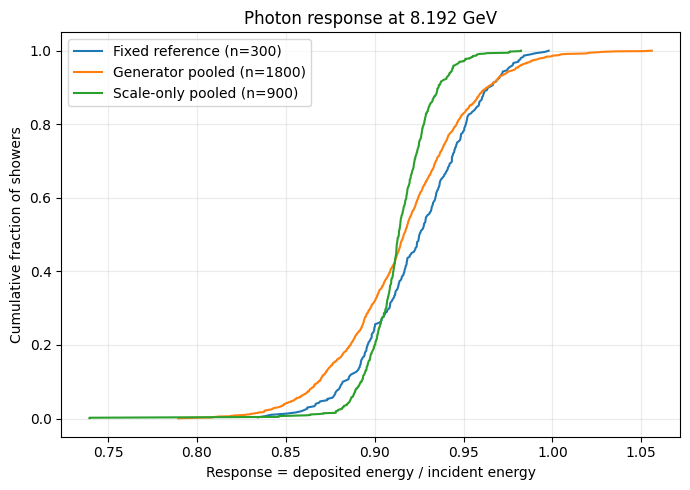

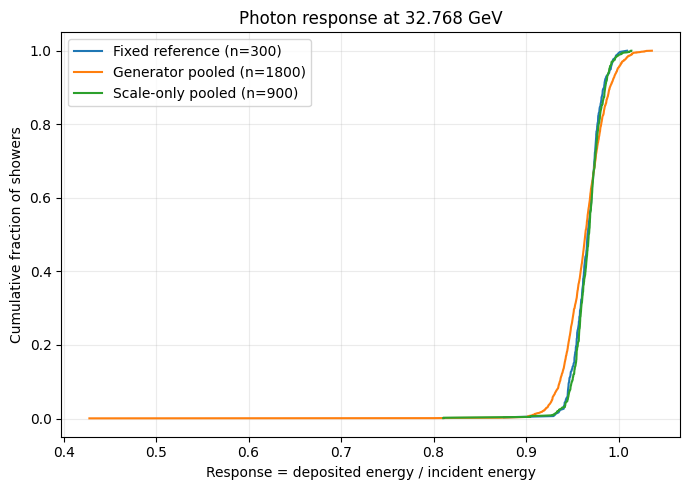

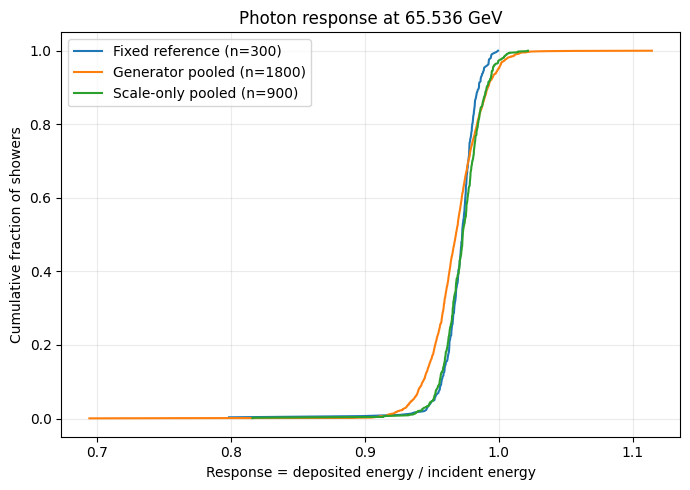

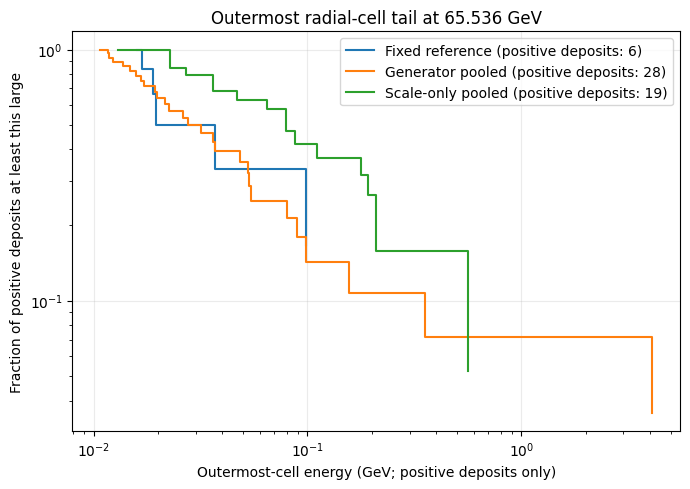

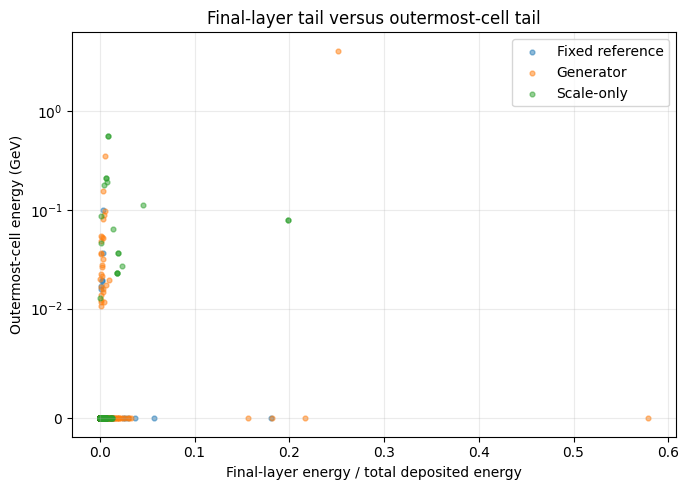

In [5]:
outdir = Path("/content/calo_tail_response_audit")
outdir.mkdir(exist_ok=True)

for E in ENERGIES:
    plt.figure(figsize=(7, 5))

    for label, kept in plot_samples[E].items():
        response = np.sort(kept.sum(axis=1) / E)
        cumulative = np.arange(1, len(response) + 1) / len(response)
        plt.plot(response, cumulative, label=f"{label} (n={len(response)})")

    plt.xlabel("Response = deposited energy / incident energy")
    plt.ylabel("Cumulative fraction of showers")
    plt.title(f"Photon response at {E} GeV")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(outdir / f"response_ecdf_{E:.3f}GeV.png", dpi=160)
    plt.show()

# Upper-tail comparison for energy deposited in the outermost cell.
E = 65.536
plt.figure(figsize=(7, 5))

for label, kept in plot_samples[E].items():
    outer = kept[:, outer_cell_index]
    positive = np.sort(outer[outer > 0])

    if len(positive):
        survival = np.arange(len(positive), 0, -1) / len(positive)
        plt.step(positive, survival, where="post",
                 label=f"{label} (positive deposits: {len(positive)})")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Outermost-cell energy (GeV; positive deposits only)")
plt.ylabel("Fraction of positive deposits at least this large")
plt.title("Outermost radial-cell tail at 65.536 GeV")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(outdir / "outermost_cell_tail_65.536GeV.png", dpi=160)
plt.show()

# Separate large final-layer fractions from large outermost-cell deposits.
plt.figure(figsize=(7, 5))

subset = events_df[events_df["energy_GeV"] == 65.536]
for method, label in [
    ("fixed_reference", "Fixed reference"),
    ("generator", "Generator"),
    ("scale_only", "Scale-only"),
]:
    s = subset[subset["method"] == method]
    plt.scatter(
        s["final_layer_fraction"], s["outermost_cell_GeV"],
        s=12, alpha=0.5, label=label
    )

plt.yscale("symlog", linthresh=0.01)
plt.xlabel("Final-layer energy / total deposited energy")
plt.ylabel("Outermost-cell energy (GeV)")
plt.title("Final-layer tail versus outermost-cell tail")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(outdir / "final_layer_vs_outermost_cell.png", dpi=160)
plt.show()

In [6]:
response_df.to_csv(outdir / "response_statistics.csv", index=False)
tail_df.to_csv(outdir / "outer_layer_tail_summary.csv", index=False)
events_df.to_csv(outdir / "event_level_tail_audit.csv", index=False)
cell_detail.to_csv(outdir / "extreme_event_cells.csv", index=False)

zip_path = "/content/calo_tail_response_audit.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in outdir.iterdir():
        z.write(p, arcname=p.name)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>